<a href="https://colab.research.google.com/github/drizzletechnova/projects/blob/main/cstr_transformer_project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Transformer-Based NMPC Project
## LSTM vs GRU vs Transformer
**Non-isothermal CSTR | Seq2Seq Forecasting | 80-step lookback → 20-step ahead**


In [1]:
#  CELL 1 — Imports & Device
import torch
import torch.nn as nn
import torch.optim as optim
import torch.optim.lr_scheduler as lr_scheduler
from torch.utils.data import Dataset, DataLoader

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import copy
import math
import warnings
warnings.filterwarnings("ignore")

from sklearn.preprocessing import StandardScaler

# ── GPU check ──────────────────────────────────────────────
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Device : {device}")

Device : cuda


In [2]:
#  CELL 2 — Load Data
from google.colab import drive
drive.mount('/content/drive')

CSV_PATH = "/content/drive/MyDrive/new_cstr_simulation_data.csv"

df = pd.read_csv(CSV_PATH)
print(f"Shape  : {df.shape}")
print(f"Columns: {list(df.columns)}")
df.head()


Mounted at /content/drive
Shape  : (689469, 6)
Columns: ['Time_s', 'CA_in_kmol_m3', 'Tin_K', 'TC_K', 'CA_out_kmol_m3', 'T_out_K']


,Time_s,CA_in_kmol_m3,Tin_K,TC_K,CA_out_kmol_m3,T_out_K
0,0.000000,0.690901,305.387343,303.384652,0.500000,350.000000
1,0.096980,0.704480,305.647077,303.808071,0.516793,346.006641
2,0.167833,0.694279,305.691535,303.588861,0.527880,343.294306
3,0.238686,0.696573,305.481121,303.325107,0.538371,340.753817
4,0.309540,0.707279,305.120504,303.137040,0.548852,338.362072


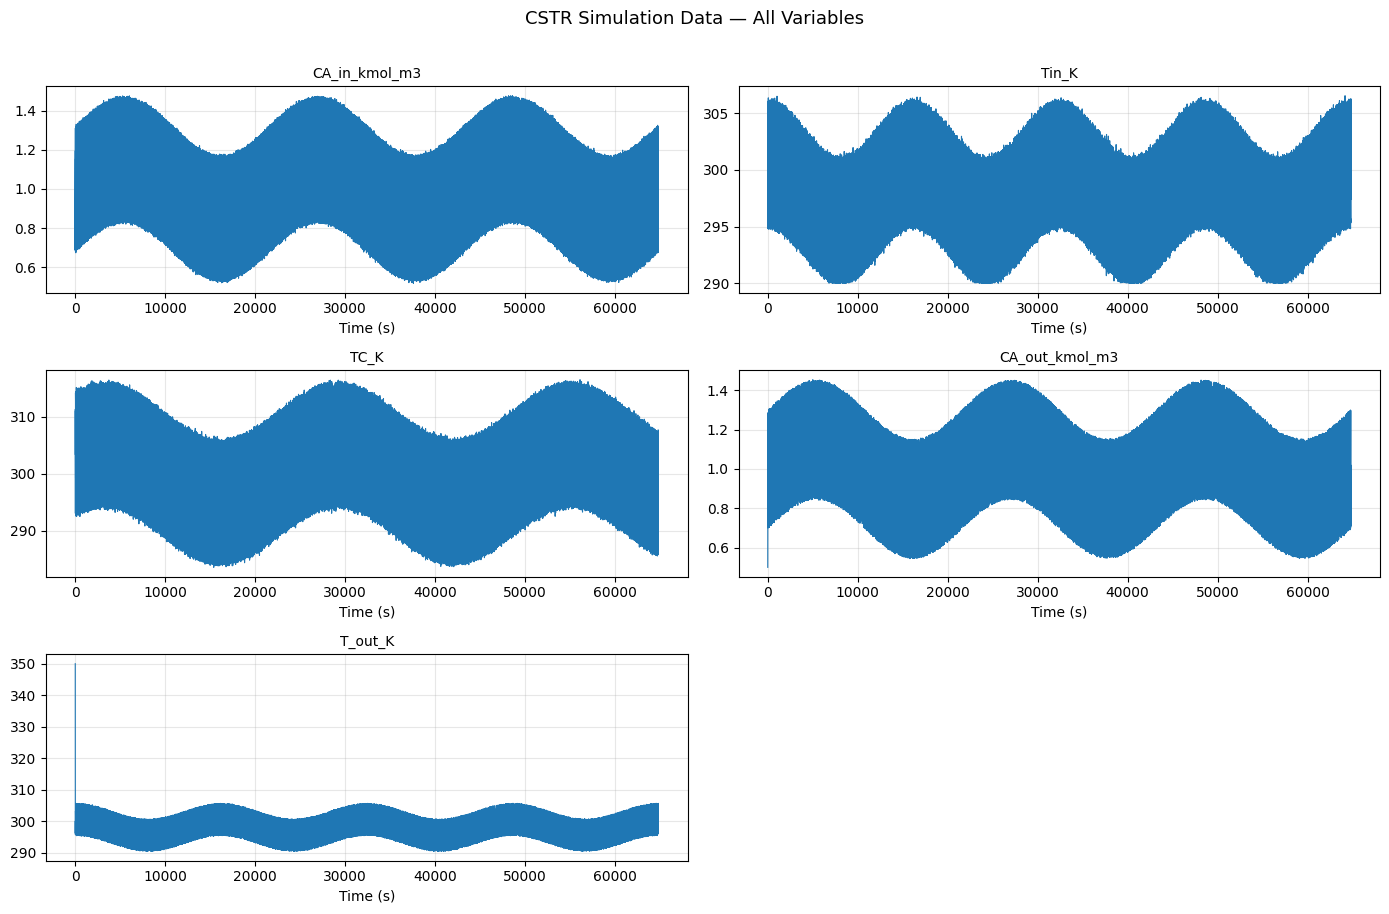

In [3]:
plot_cols = [c for c in df.columns if c != "Time_s"]
n_plots   = len(plot_cols)
ncols     = 2
nrows     = math.ceil(n_plots / ncols)

fig, axes = plt.subplots(nrows, ncols, figsize=(14, nrows * 3))
axes = axes.flatten()

time = df["Time_s"] if "Time_s" in df.columns else df.index

for i, col in enumerate(plot_cols):
    axes[i].plot(time, df[col], linewidth=0.8)
    axes[i].set_title(col, fontsize=10)
    axes[i].set_xlabel("Time (s)")
    axes[i].grid(True, alpha=0.3)

for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.suptitle("CSTR Simulation Data — All Variables", fontsize=13, y=1.01)
plt.tight_layout()
plt.show()


In [4]:
#  CELL 4 — Preprocessing & Train/Val/Test Split
# Drop time column
if "Time_s" in df.columns:
    df = df.drop("Time_s", axis=1)

INPUT_COLS  = ["CA_in_kmol_m3", "Tin_K",      "TC_K"]
TARGET_COLS = ["CA_out_kmol_m3", "T_out_K"]

# ── Chronological split (NEVER shuffle time series) ────────
n         = len(df)
train_end = int(0.70 * n)
val_end   = int(0.85 * n)

train_df = df.iloc[:train_end].copy()
val_df   = df.iloc[train_end:val_end].copy()
test_df  = df.iloc[val_end:].copy()

print(f"Train : {len(train_df):>7,} rows")
print(f"Val   : {len(val_df):>7,} rows")
print(f"Test  : {len(test_df):>7,} rows")

# ── Scale (fit ONLY on train) ───────────────────────────────
scaler_X = StandardScaler()
scaler_y = StandardScaler()

X_train = scaler_X.fit_transform(train_df[INPUT_COLS])
y_train = scaler_y.fit_transform(train_df[TARGET_COLS])

X_val   = scaler_X.transform(val_df[INPUT_COLS])
y_val   = scaler_y.transform(val_df[TARGET_COLS])

X_test  = scaler_X.transform(test_df[INPUT_COLS])
y_test  = scaler_y.transform(test_df[TARGET_COLS])

print(f"\nX_train mean ≈ {X_train.mean(axis=0).round(4)}")
print(f"X_train std  ≈ {X_train.std(axis=0).round(4)}")


Train : 482,628 rows
Val   : 103,420 rows
Test  : 103,421 rows

X_train mean ≈ [ 0. -0. -0.]
X_train std  ≈ [1. 1. 1.]


In [5]:

T = 80    # lookback window
H = 20    # prediction horizon

class Seq2SeqDataset(Dataset):
    def __init__(self, inputs, targets, T=80, H=20):
        self.inputs  = torch.tensor(inputs,  dtype=torch.float32)
        self.targets = torch.tensor(targets, dtype=torch.float32)
        self.T = T
        self.H = H
        self.length = len(inputs) - T - H + 1

    def __len__(self):
        return self.length

    def __getitem__(self, idx):
        x = self.inputs [idx: idx + self.T]
        y = self.targets[idx + self.T : idx + self.T + self.H]
        return x, y

BATCH = 128

train_ds = Seq2SeqDataset(X_train, y_train, T, H)
val_ds   = Seq2SeqDataset(X_val,   y_val,   T, H)
test_ds  = Seq2SeqDataset(X_test,  y_test,  T, H)

train_loader = DataLoader(train_ds, batch_size=BATCH, shuffle=True,  pin_memory=True, num_workers=2)
val_loader   = DataLoader(val_ds,   batch_size=BATCH, shuffle=False, pin_memory=True, num_workers=2)
test_loader  = DataLoader(test_ds,  batch_size=BATCH, shuffle=False, pin_memory=True, num_workers=2)

xb, yb = next(iter(train_loader))
print(f"Input  batch shape : {xb.shape}   (batch, lookback, features)")
print(f"Target batch shape : {yb.shape}   (batch, horizon, outputs)")
print(f"\nTrain batches : {len(train_loader)}")
print(f"Val   batches : {len(val_loader)}")


Input  batch shape : torch.Size([128, 80, 3])   (batch, lookback, features)
Target batch shape : torch.Size([128, 20, 2])   (batch, horizon, outputs)

Train batches : 3770
Val   batches : 808


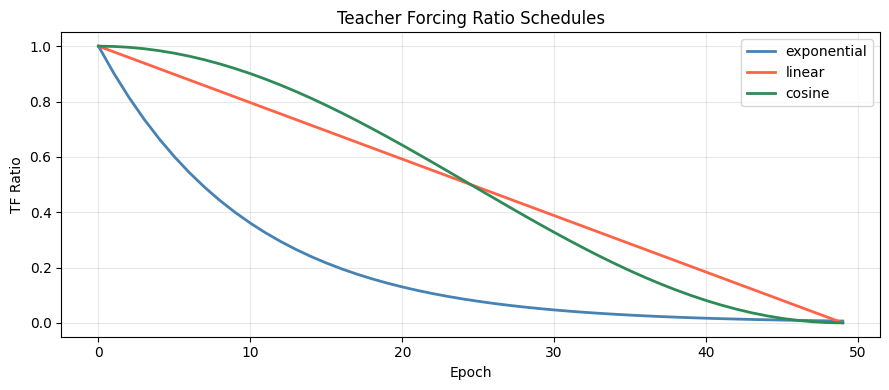

In [6]:
# Teacher Forcing Schedule
def get_tf_ratio(epoch, total_epochs, start=1.0, end=0.0,
                 schedule="exponential"):
    progress = epoch / max(total_epochs - 1, 1)   # 0 → 1

    if schedule == "linear":
        return max(end, start + (end - start) * progress)

    elif schedule == "exponential":
        k = 5.0
        return max(end, start * math.exp(-k * progress))

    elif schedule == "cosine":
        return end + 0.5 * (start - end) * (1 + math.cos(math.pi * progress))

    return start

# ── Preview the three schedules ────────────────────────────
epochs_preview = 50
fig, ax = plt.subplots(figsize=(9, 4))
for sched, col in [("exponential","steelblue"),("linear","tomato"),("cosine","seagreen")]:
    ratios = [get_tf_ratio(e, epochs_preview, schedule=sched) for e in range(epochs_preview)]
    ax.plot(ratios, label=sched, color=col, lw=2)

ax.set_title("Teacher Forcing Ratio Schedules", fontsize=12)
ax.set_xlabel("Epoch"); ax.set_ylabel("TF Ratio")
ax.legend(); ax.grid(True, alpha=0.3)
plt.tight_layout(); plt.show()


In [7]:
# ============================================================
#  CELL 7 — LSTM Seq2Seq Model
# ============================================================
class LSTMSeq2Seq(nn.Module):
    def __init__(self, input_dim=3, hidden_dim=128,
                 num_layers=2, dropout=0.3, output_dim=2):
        super().__init__()
        self.output_dim = output_dim

        # num_layers=2 → dropout is active BETWEEN layers
        self.encoder = nn.LSTM(input_dim,  hidden_dim,
                               num_layers=num_layers,
                               batch_first=True, dropout=dropout)
        self.decoder = nn.LSTM(output_dim, hidden_dim,
                               num_layers=num_layers,
                               batch_first=True, dropout=dropout)
        self.fc = nn.Linear(hidden_dim, output_dim)

    def forward(self, x, y=None, H=20, teacher_forcing_ratio=0.0):
        B = x.size(0)

        # Encode the lookback window
        _, (h, c) = self.encoder(x)                     # h: (num_layers, B, hidden)

        # Decoder start token
        dec_in = torch.zeros(B, 1, self.output_dim, device=x.device)

        outputs = []
        for t in range(H):
            out, (h, c) = self.decoder(dec_in, (h, c))
            pred = self.fc(out)                          # (B, 1, output_dim)
            outputs.append(pred)

            use_teacher = (
                self.training
                and y is not None
                and torch.rand(1).item() < teacher_forcing_ratio
            )
            dec_in = y[:, t:t+1, :] if use_teacher else pred

        return torch.cat(outputs, dim=1)                 # (B, H, output_dim)


# ── Sanity check ───────────────────────────────────────────
_m = LSTMSeq2Seq().to(device)
_x = torch.randn(4, 80, 3).to(device)
_y = torch.randn(4, 20, 2).to(device)
print(f"LSTM output shape : {_m(_x, _y, teacher_forcing_ratio=0.5).shape}")
print(f"Parameters        : {sum(p.numel() for p in _m.parameters()):,}")
del _m, _x, _y


LSTM output shape : torch.Size([4, 20, 2])
Parameters        : 400,130


In [8]:
#GRU Seq2Seq Model
class GRUSeq2Seq(nn.Module):
    def __init__(self, input_dim=3, hidden_dim=256,
                 num_layers=2, dropout=0.2, output_dim=2):
        super().__init__()
        self.output_dim = output_dim

        self.encoder = nn.GRU(input_dim,  hidden_dim,
                              num_layers=num_layers,
                              batch_first=True, dropout=dropout)
        self.decoder = nn.GRU(output_dim, hidden_dim,
                              num_layers=num_layers,
                              batch_first=True, dropout=dropout)
        self.fc = nn.Linear(hidden_dim, output_dim)

    def forward(self, x, y=None, H=20, teacher_forcing_ratio=0.0):
        B = x.size(0)

        _, h = self.encoder(x)                           # h: (num_layers, B, hidden)

        dec_in = torch.zeros(B, 1, self.output_dim, device=x.device)

        outputs = []
        for t in range(H):
            out, h = self.decoder(dec_in, h)
            pred   = self.fc(out)
            outputs.append(pred)

            use_teacher = (
                self.training
                and y is not None
                and torch.rand(1).item() < teacher_forcing_ratio
            )
            dec_in = y[:, t:t+1, :] if use_teacher else pred

        return torch.cat(outputs, dim=1)                 # (B, H, output_dim)


# ── Sanity check ───────────────────────────────────────────
_m = GRUSeq2Seq().to(device)
_x = torch.randn(4, 80, 3).to(device)
_y = torch.randn(4, 20, 2).to(device)
print(f"GRU output shape  : {_m(_x, _y, teacher_forcing_ratio=0.5).shape}")
print(f"Parameters        : {sum(p.numel() for p in _m.parameters()):,}")
del _m, _x, _y


GRU output shape  : torch.Size([4, 20, 2])
Parameters        : 1,190,146


In [9]:
#Transformer Encoder-Only Model
class PositionalEncoding(nn.Module):
    def __init__(self, d_model, max_len=500, dropout=0.1):
        super().__init__()
        self.dropout = nn.Dropout(dropout)

        pe  = torch.zeros(max_len, d_model)
        pos = torch.arange(0, max_len).unsqueeze(1).float()
        div = torch.exp(
            torch.arange(0, d_model, 2).float() * (-math.log(10000.0) / d_model)
        )
        pe[:, 0::2] = torch.sin(pos * div)
        pe[:, 1::2] = torch.cos(pos * div)
        pe = pe.unsqueeze(0)                             # (1, max_len, d_model)
        self.register_buffer("pe", pe)

    def forward(self, x):
        x = x + self.pe[:, :x.size(1), :]
        return self.dropout(x)


class CSTRTransformer(nn.Module):
    def __init__(self, input_dim=3, output_dim=2, d_model=128,
                 nhead=8, num_layers=3, dim_ff=512,
                 dropout=0.1, lookback=80, horizon=20):
        super().__init__()
        assert d_model % nhead == 0, "d_model must be divisible by nhead"

        self.horizon    = horizon
        self.output_dim = output_dim

        self.input_proj = nn.Linear(input_dim, d_model)
        self.pos_enc    = PositionalEncoding(d_model, dropout=dropout)

        enc_layer = nn.TransformerEncoderLayer(
            d_model=d_model, nhead=nhead,
            dim_feedforward=dim_ff,
            dropout=dropout,
            batch_first=True,           # (B, seq, features)  ← essential
            norm_first=True             # Pre-LayerNorm: more stable training
        )
        self.encoder = nn.TransformerEncoder(enc_layer, num_layers=num_layers)

        self.head = nn.Sequential(
            nn.Linear(d_model, d_model),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(d_model, output_dim * horizon)
        )

    def forward(self, x):
        # x: (B, T, input_dim)
        x = self.input_proj(x)           # → (B, T, d_model)
        x = self.pos_enc(x)              # → (B, T, d_model)
        x = self.encoder(x)              # → (B, T, d_model)
        x = x[:, -1, :]                  # → (B, d_model)  last token summary
        x = self.head(x)                 # → (B, H*output_dim)
        return x.view(-1, self.horizon, self.output_dim)   # → (B, H, output_dim)


# ── Sanity check ───────────────────────────────────────────
_m = CSTRTransformer().to(device)
_x = torch.randn(4, 80, 3).to(device)
print(f"Transformer output : {_m(_x).shape}")
print(f"Parameters         : {sum(p.numel() for p in _m.parameters()):,}")
del _m, _x


Transformer output : torch.Size([4, 20, 2])
Parameters         : 617,000


In [10]:
# Train & Validation Epoch Functions
loss_fn = nn.MSELoss()

def train_epoch(loader, model, optimiser, tf_ratio=0.0):
    model.train()
    total = 0.0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        try:
            pred = model(x, y, teacher_forcing_ratio=tf_ratio)
        except TypeError:
            pred = model(x)

        loss = loss_fn(pred, y)

        optimiser.zero_grad()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimiser.step()

        total += loss.item()

    return total / len(loader)


def val_epoch(loader, model):
    model.eval()
    total = 0.0
    with torch.inference_mode():
        for x, y in loader:
            x, y = x.to(device), y.to(device)

            # Always fully autoregressive during validation
            try:
                pred = model(x, H=y.shape[1], teacher_forcing_ratio=0.0)
            except TypeError:
                pred = model(x)

            total += loss_fn(pred, y).item()

    return total / len(loader)


In [11]:
#Unified Training Loop
def train_model(model, optimiser, train_loader, val_loader,
                epochs=50, model_name="model",
                tf_schedule="exponential",
                use_teacher_forcing=True):
    scheduler = lr_scheduler.CosineAnnealingWarmRestarts(
        optimiser, T_0=10, T_mult=2, eta_min=1e-6
    )

    best_val   = float("inf")
    best_state = None

    train_losses = []
    val_losses   = []
    tf_ratios    = []

    for epoch in range(epochs):
        tf = (get_tf_ratio(epoch, epochs, schedule=tf_schedule)
              if use_teacher_forcing else 0.0)

        tr_loss  = train_epoch(train_loader, model, optimiser, tf)
        val_loss = val_epoch(val_loader, model)

        scheduler.step(epoch + val_loss)

        if val_loss < best_val:
            best_val   = val_loss
            best_state = copy.deepcopy(model.state_dict())

        train_losses.append(tr_loss)
        val_losses.append(val_loss)
        tf_ratios.append(tf)

        lr = optimiser.param_groups[0]["lr"]
        print(f"[{model_name}] {epoch+1:>3}/{epochs}  "
              f"train={tr_loss:.5f}  val={val_loss:.5f}  "
              f"tf={tf:.3f}  lr={lr:.2e}")

    model.load_state_dict(best_state)
    print(f"\n✓ {model_name} — best val loss: {best_val:.5f}\n")
    return train_losses, val_losses, tf_ratios


In [12]:
# — Train LSTM
EPOCHS = 20

lstm_model = LSTMSeq2Seq(
    input_dim=3, hidden_dim=128,
    num_layers=2, dropout=0.3, output_dim=2
).to(device)

lstm_opt = optim.Adam(lstm_model.parameters(), lr=3e-4, weight_decay=1e-4)

lstm_train_loss, lstm_val_loss, lstm_tf = train_model(
    lstm_model, lstm_opt, train_loader, val_loader,
    epochs=EPOCHS, model_name="LSTM",
    tf_schedule="exponential", use_teacher_forcing=True
)


[LSTM]   1/20  train=0.01747  val=0.15739  tf=1.000  lr=3.00e-04
[LSTM]   2/20  train=0.00505  val=0.16197  tf=0.769  lr=2.90e-04
[LSTM]   3/20  train=0.00826  val=0.13441  tf=0.591  lr=2.68e-04
[LSTM]   4/20  train=0.01287  val=0.13736  tf=0.454  lr=2.33e-04
[LSTM]   5/20  train=0.01911  val=0.13142  tf=0.349  lr=1.91e-04
[LSTM]   6/20  train=0.02744  val=0.12289  tf=0.268  lr=1.45e-04
[LSTM]   7/20  train=0.03615  val=0.11020  tf=0.206  lr=9.94e-05
[LSTM]   8/20  train=0.04796  val=0.11983  tf=0.158  lr=5.81e-05
[LSTM]   9/20  train=0.05541  val=0.10857  tf=0.122  lr=2.66e-05
[LSTM]  10/20  train=0.06557  val=0.11179  tf=0.094  lr=6.78e-06
[LSTM]  11/20  train=0.07380  val=0.10993  tf=0.072  lr=3.00e-04
[LSTM]  12/20  train=0.09175  val=0.12645  tf=0.055  lr=2.98e-04
[LSTM]  13/20  train=0.09331  val=0.10935  tf=0.043  lr=2.92e-04
[LSTM]  14/20  train=0.09680  val=0.11317  tf=0.033  lr=2.82e-04
[LSTM]  15/20  train=0.09831  val=0.10634  tf=0.025  lr=2.70e-04
[LSTM]  16/20  train=0.09

In [13]:
# Train GRU
gru_model = GRUSeq2Seq(
    input_dim=3, hidden_dim=256,
    num_layers=2, dropout=0.2, output_dim=2
).to(device)

gru_opt = optim.Adam(gru_model.parameters(), lr=3e-4, weight_decay=1e-4)

gru_train_loss, gru_val_loss, gru_tf = train_model(
    gru_model, gru_opt, train_loader, val_loader,
    epochs=EPOCHS, model_name="GRU",
    tf_schedule="exponential", use_teacher_forcing=True
)


[GRU]   1/20  train=0.00736  val=0.14498  tf=1.000  lr=3.00e-04
[GRU]   2/20  train=0.00390  val=0.14409  tf=0.769  lr=2.90e-04
[GRU]   3/20  train=0.00736  val=0.18988  tf=0.591  lr=2.66e-04
[GRU]   4/20  train=0.01180  val=0.21893  tf=0.454  lr=2.30e-04
[GRU]   5/20  train=0.01744  val=0.11870  tf=0.349  lr=1.91e-04
[GRU]   6/20  train=0.02500  val=0.14449  tf=0.268  lr=1.44e-04
[GRU]   7/20  train=0.03343  val=0.11345  tf=0.206  lr=9.93e-05
[GRU]   8/20  train=0.04307  val=0.11795  tf=0.158  lr=5.82e-05
[GRU]   9/20  train=0.05317  val=0.10761  tf=0.122  lr=2.67e-05
[GRU]  10/20  train=0.06216  val=0.10857  tf=0.094  lr=6.82e-06
[GRU]  11/20  train=0.07135  val=0.10867  tf=0.072  lr=3.00e-04
[GRU]  12/20  train=0.08762  val=0.12397  tf=0.055  lr=2.98e-04
[GRU]  13/20  train=0.09093  val=0.10498  tf=0.043  lr=2.92e-04
[GRU]  14/20  train=0.09493  val=0.10935  tf=0.033  lr=2.83e-04
[GRU]  15/20  train=0.09696  val=0.11173  tf=0.025  lr=2.70e-04
[GRU]  16/20  train=0.09868  val=0.11440

In [14]:
#  Train Transformer
transformer_model = CSTRTransformer(
    input_dim=3, output_dim=2,
    d_model=128, nhead=8,
    num_layers=3, dim_ff=512,
    dropout=0.1, lookback=80, horizon=20
).to(device)

transformer_opt = optim.Adam(
    transformer_model.parameters(), lr=1e-4, weight_decay=1e-4
)

trans_train_loss, trans_val_loss, _ = train_model(
    transformer_model, transformer_opt, train_loader, val_loader,
    epochs=EPOCHS, model_name="Transformer",
    use_teacher_forcing=False
)


[Transformer]   1/20  train=0.13345  val=0.10449  tf=0.000  lr=1.00e-04
[Transformer]   2/20  train=0.10864  val=0.10676  tf=0.000  lr=9.70e-05
[Transformer]   3/20  train=0.10669  val=0.10422  tf=0.000  lr=8.96e-05
[Transformer]   4/20  train=0.10584  val=0.10355  tf=0.000  lr=7.83e-05
[Transformer]   5/20  train=0.10548  val=0.10388  tf=0.000  lr=6.43e-05
[Transformer]   6/20  train=0.10518  val=0.10258  tf=0.000  lr=4.89e-05
[Transformer]   7/20  train=0.10492  val=0.10256  tf=0.000  lr=3.37e-05
[Transformer]   8/20  train=0.10467  val=0.10394  tf=0.000  lr=2.01e-05
[Transformer]   9/20  train=0.10457  val=0.10355  tf=0.000  lr=9.53e-06
[Transformer]  10/20  train=0.10434  val=0.10343  tf=0.000  lr=2.95e-06
[Transformer]  11/20  train=0.10436  val=0.10396  tf=0.000  lr=1.00e-04
[Transformer]  12/20  train=0.10506  val=0.10450  tf=0.000  lr=9.93e-05
[Transformer]  13/20  train=0.10506  val=0.10442  tf=0.000  lr=9.73e-05
[Transformer]  14/20  train=0.10491  val=0.10378  tf=0.000  lr=9

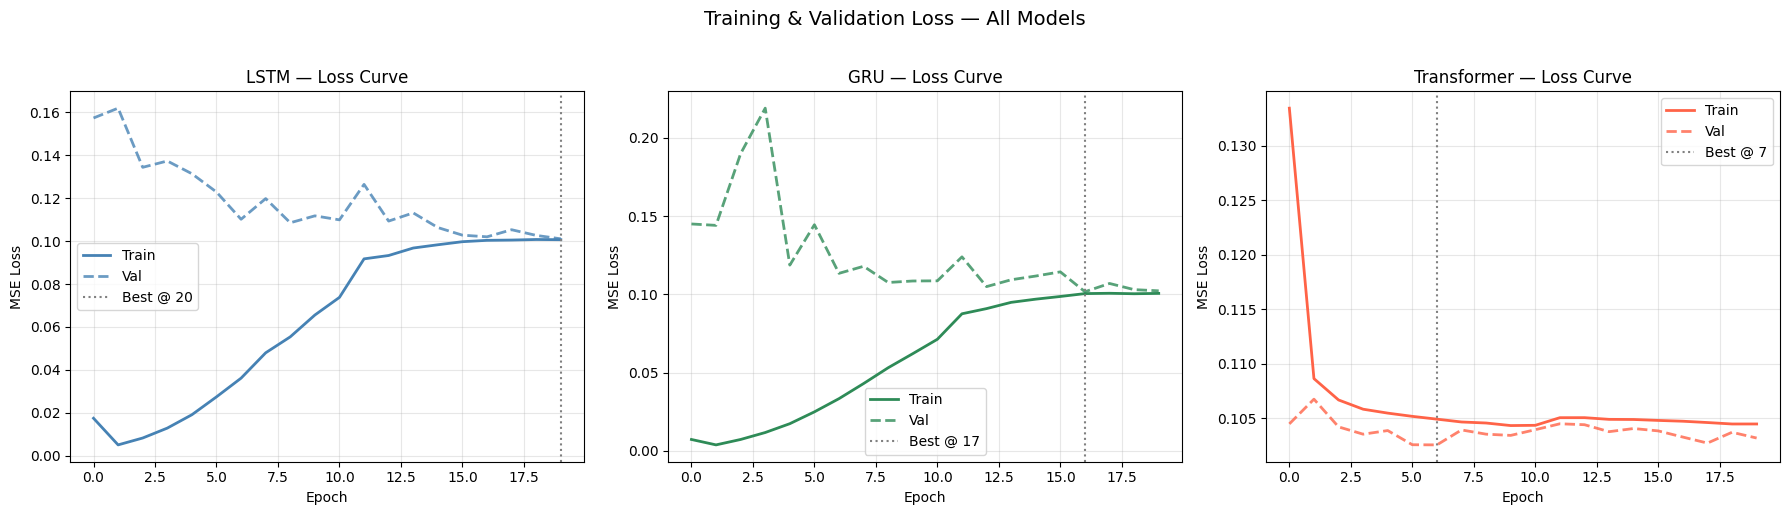

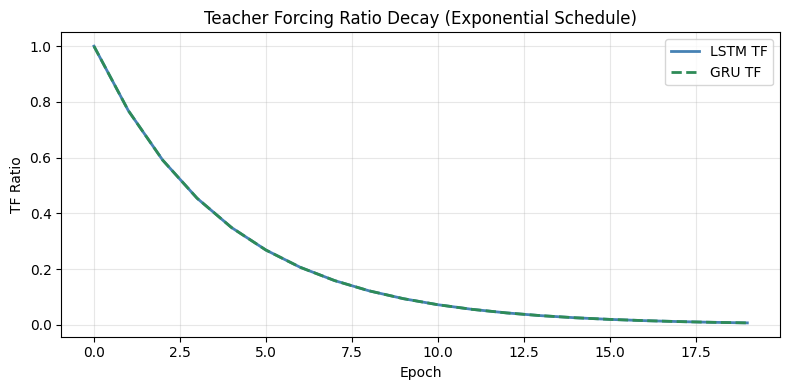

In [15]:
# Training Curve Plots
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

models_curves = [
    ("LSTM",        lstm_train_loss,  lstm_val_loss,  "steelblue"),
    ("GRU",         gru_train_loss,   gru_val_loss,   "seagreen"),
    ("Transformer", trans_train_loss, trans_val_loss, "tomato"),
]

for ax, (name, tr, vl, col) in zip(axes, models_curves):
    ax.plot(tr, color=col,       lw=2,   label="Train")
    ax.plot(vl, color=col, ls="--", lw=2, label="Val", alpha=0.8)
    ax.set_title(f"{name} — Loss Curve", fontsize=12)
    ax.set_xlabel("Epoch"); ax.set_ylabel("MSE Loss")
    ax.legend(); ax.grid(True, alpha=0.3)
    best_epoch = int(np.argmin(vl))
    ax.axvline(best_epoch, color="gray", ls=":", lw=1.5,
               label=f"Best @ {best_epoch+1}")
    ax.legend()

plt.suptitle("Training & Validation Loss — All Models", fontsize=14, y=1.02)
plt.tight_layout()
plt.savefig("training_curves.png", dpi=150, bbox_inches="tight")
plt.show()

# ── Teacher forcing decay ───────────────────────────────────
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(lstm_tf, "steelblue", lw=2, label="LSTM TF")
ax.plot(gru_tf,  "seagreen",  lw=2, ls="--", label="GRU TF")
ax.set_title("Teacher Forcing Ratio Decay (Exponential Schedule)", fontsize=12)
ax.set_xlabel("Epoch"); ax.set_ylabel("TF Ratio")
ax.legend(); ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("tf_decay.png", dpi=150, bbox_inches="tight")
plt.show()


In [22]:
# Save Model Checkpoints to Drive
import os

SAVE_DIR = "/content/drive/MyDrive/cstr_models"
os.makedirs(SAVE_DIR, exist_ok=True)

torch.save({
    "model_state": lstm_model.state_dict(),
    "train_loss":  lstm_train_loss,
    "val_loss":    lstm_val_loss,
}, os.path.join(SAVE_DIR, "lstm_best.pt"))

torch.save({
    "model_state": gru_model.state_dict(),
    "train_loss":  gru_train_loss,
    "val_loss":    gru_val_loss,
}, os.path.join(SAVE_DIR, "gru_best.pt"))

torch.save({
    "model_state": transformer_model.state_dict(),
    "train_loss":  trans_train_loss,
    "val_loss":    trans_val_loss,
}, os.path.join(SAVE_DIR, "transformer_best.pt"))

# Also save scalers for NMPC integration later
import pickle
with open(os.path.join(SAVE_DIR, "scaler_X.pkl"), "wb") as f:
    pickle.dump(scaler_X, f)
with open(os.path.join(SAVE_DIR, "scaler_y.pkl"), "wb") as f:
    pickle.dump(scaler_y, f)

print("✓ All checkpoints and scalers saved to Google Drive")
print(f"  {SAVE_DIR}/")
for fname in os.listdir(SAVE_DIR):
    size = os.path.getsize(os.path.join(SAVE_DIR, fname))
    print(f"    {fname:<30} {size/1024:.1f} KB")


✓ All checkpoints and scalers saved to Google Drive
  /content/drive/MyDrive/cstr_models/
    lstm_best.pt                   1567.1 KB
    gru_best.pt                    4653.2 KB
    transformer_best.pt            2676.7 KB
    scaler_X.pkl                   0.6 KB
    scaler_y.pkl                   0.6 KB


In [16]:
# Unified Rollout Evaluator
def rollout_evaluation(model, X, y, T, H, device,
                        model_type="transformer", model_name="Model"):
    """
    Fully autoregressive evaluation: slide a window of T steps,
    predict H steps, shift forward H, repeat.

    Parameters
    ----------
    model_type : 'transformer' | 'seq2seq'
    """
    model.eval()
    X_t = torch.tensor(X, dtype=torch.float32).to(device)
    y_t = torch.tensor(y, dtype=torch.float32).to(device)

    preds   = []
    targets = []
    t       = 0
    N       = len(X)

    with torch.no_grad():
        x_win = X_t[:T].unsqueeze(0)          # (1, T, input_dim)

        while t + T + H <= N:
            if model_type == "transformer":
                y_pred = model(x_win)
            else:
                y_pred = model(x_win, H=H, teacher_forcing_ratio=0.0)

            preds.append(y_pred.squeeze(0))
            targets.append(y_t[t + T : t + T + H])

            # slide window forward by H
            x_win = torch.cat([
                x_win[:, H:, :],
                X_t[t + T : t + T + H].unsqueeze(0)
            ], dim=1)

            t += H

    preds   = torch.cat(preds,   dim=0)   # (N_windows*H, output_dim)
    targets = torch.cat(targets, dim=0)

    # ── Metrics ────────────────────────────────────────────
    mse_vec = torch.mean((preds - targets) ** 2, dim=0)
    mae_vec = torch.mean(torch.abs(preds - targets), dim=0)
    rmse_vec = torch.sqrt(mse_vec)
    overall_mse = torch.mean((preds - targets) ** 2).item()

    print(f"\n{'═'*46}")
    print(f"  {model_name} — Rollout Metrics (scaled space)")
    print(f"{'─'*46}")
    print(f"  {'Metric':<12} {'CA_out':>12} {'T_out':>12}")
    print(f"{'─'*46}")
    print(f"  {'MSE':<12} {mse_vec[0].item():>12.6f} {mse_vec[1].item():>12.6f}")
    print(f"  {'RMSE':<12} {rmse_vec[0].item():>12.6f} {rmse_vec[1].item():>12.6f}")
    print(f"  {'MAE':<12} {mae_vec[0].item():>12.6f} {mae_vec[1].item():>12.6f}")
    print(f"{'─'*46}")
    print(f"  {'Overall MSE':<12} {overall_mse:>12.6f}")
    print(f"{'═'*46}")

    return overall_mse, preds.cpu().numpy(), targets.cpu().numpy()


In [17]:

#Save Model Checkpoints to Drive

import os

SAVE_DIR = "/content/drive/MyDrive/cstr_models"
os.makedirs(SAVE_DIR, exist_ok=True)

torch.save({
    "model_state": lstm_model.state_dict(),
    "train_loss":  lstm_train_loss,
    "val_loss":    lstm_val_loss,
}, os.path.join(SAVE_DIR, "lstm_best.pt"))

torch.save({
    "model_state": gru_model.state_dict(),
    "train_loss":  gru_train_loss,
    "val_loss":    gru_val_loss,
}, os.path.join(SAVE_DIR, "gru_best.pt"))

torch.save({
    "model_state": transformer_model.state_dict(),
    "train_loss":  trans_train_loss,
    "val_loss":    trans_val_loss,
}, os.path.join(SAVE_DIR, "transformer_best.pt"))

# Also save scalers for NMPC integration later
import pickle
with open(os.path.join(SAVE_DIR, "scaler_X.pkl"), "wb") as f:
    pickle.dump(scaler_X, f)
with open(os.path.join(SAVE_DIR, "scaler_y.pkl"), "wb") as f:
    pickle.dump(scaler_y, f)

print("✓ All checkpoints and scalers saved to Google Drive")
print(f"  {SAVE_DIR}/")
for fname in os.listdir(SAVE_DIR):
    size = os.path.getsize(os.path.join(SAVE_DIR, fname))
    print(f"    {fname:<30} {size/1024:.1f} KB")


✓ All checkpoints and scalers saved to Google Drive
  /content/drive/MyDrive/cstr_models/
    lstm_best.pt                   1567.1 KB
    gru_best.pt                    4653.2 KB
    transformer_best.pt            2676.7 KB
    scaler_X.pkl                   0.6 KB
    scaler_y.pkl                   0.6 KB


In [18]:

# Run Rollout Evaluation on Test Set
lstm_mse,  lstm_preds,  lstm_targets = rollout_evaluation(
    lstm_model,  X_test, y_test, T, H, device,
    model_type="seq2seq", model_name="LSTM"
)

gru_mse,   gru_preds,   gru_targets  = rollout_evaluation(
    gru_model,   X_test, y_test, T, H, device,
    model_type="seq2seq", model_name="GRU"
)

trans_mse, trans_preds, trans_targets = rollout_evaluation(
    transformer_model, X_test, y_test, T, H, device,
    model_type="transformer", model_name="Transformer"
)



══════════════════════════════════════════════
  LSTM — Rollout Metrics (scaled space)
──────────────────────────────────────────────
  Metric             CA_out        T_out
──────────────────────────────────────────────
  MSE              0.089191     0.115847
  RMSE             0.298649     0.340363
  MAE              0.174700     0.208360
──────────────────────────────────────────────
  Overall MSE      0.102519
══════════════════════════════════════════════

══════════════════════════════════════════════
  GRU — Rollout Metrics (scaled space)
──────────────────────────────────────────────
  Metric             CA_out        T_out
──────────────────────────────────────────────
  MSE              0.094921     0.115441
  RMSE             0.308093     0.339766
  MAE              0.190395     0.198054
──────────────────────────────────────────────
  Overall MSE      0.105181
══════════════════════════════════════════════

══════════════════════════════════════════════
  Transformer — R

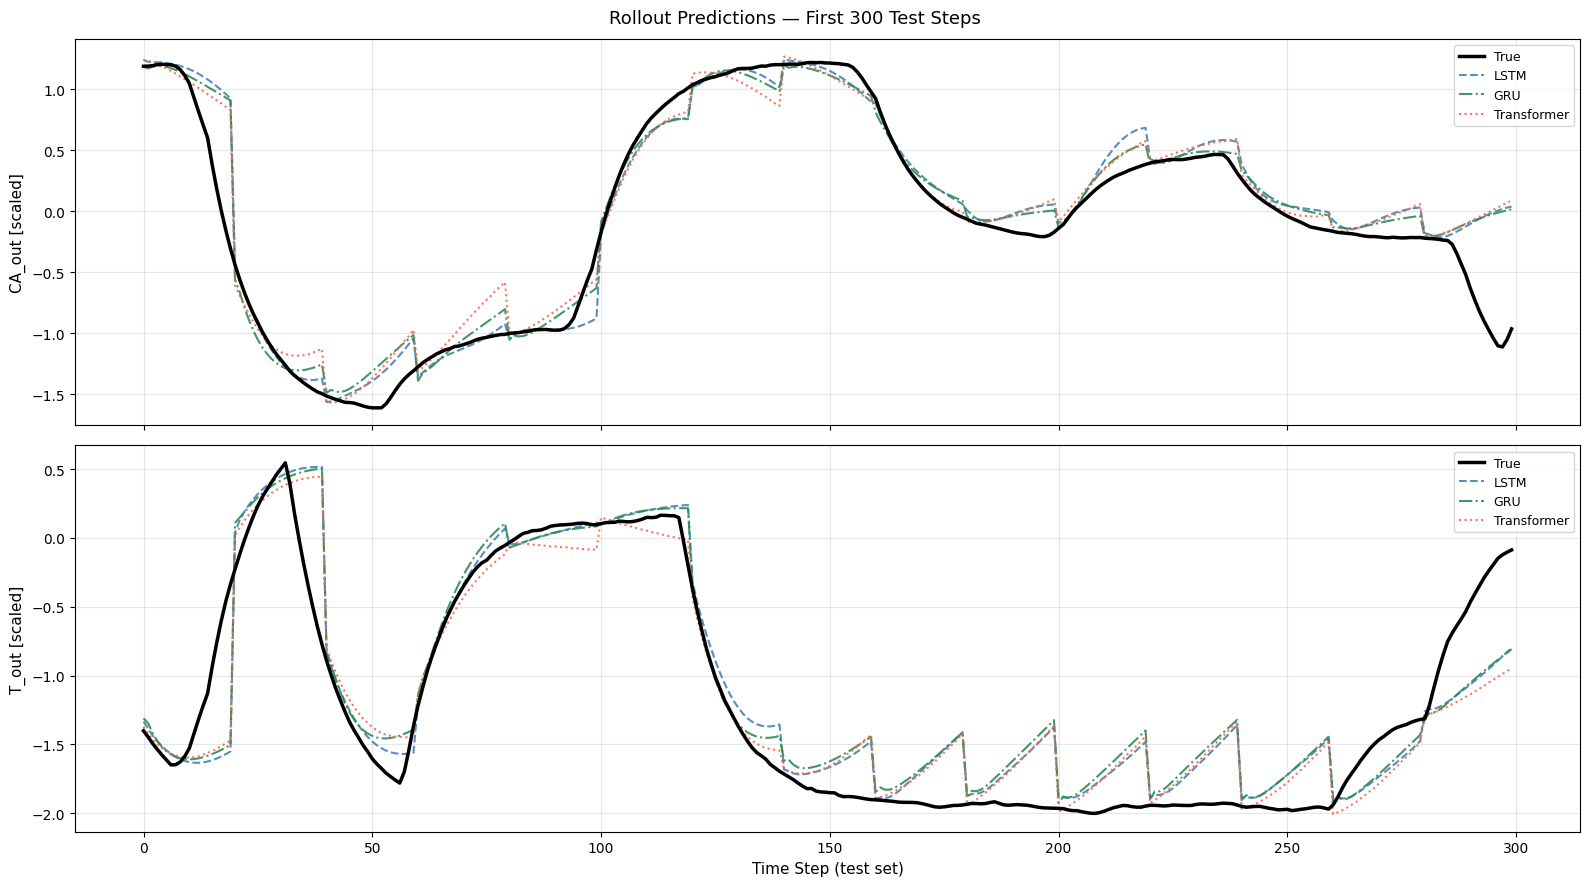

In [19]:
N_SHOW = 300    # number of test steps to display

fig, axes = plt.subplots(2, 1, figsize=(16, 9), sharex=True)

output_labels = ["CA_out [scaled]", "T_out [scaled]"]
colors = {"LSTM":"steelblue", "GRU":"seagreen", "Transformer":"tomato"}

for oi, ax in enumerate(axes):
    ax.plot(trans_targets[:N_SHOW, oi], "k-", lw=2.5, label="True", zorder=5)
    ax.plot(lstm_preds[:N_SHOW, oi],  color="steelblue", lw=1.5, ls="--", label="LSTM",        alpha=0.9)
    ax.plot(gru_preds[:N_SHOW, oi],   color="seagreen",  lw=1.5, ls="-.", label="GRU",         alpha=0.9)
    ax.plot(trans_preds[:N_SHOW, oi], color="tomato",    lw=1.5, ls=":",  label="Transformer", alpha=0.9)

    ax.set_ylabel(output_labels[oi], fontsize=11)
    ax.legend(loc="upper right", fontsize=9)
    ax.grid(True, alpha=0.3)

axes[-1].set_xlabel("Time Step (test set)", fontsize=11)
plt.suptitle(f"Rollout Predictions — First {N_SHOW} Test Steps", fontsize=13)
plt.tight_layout()
plt.savefig("predictions_all.png", dpi=150, bbox_inches="tight")
plt.show()


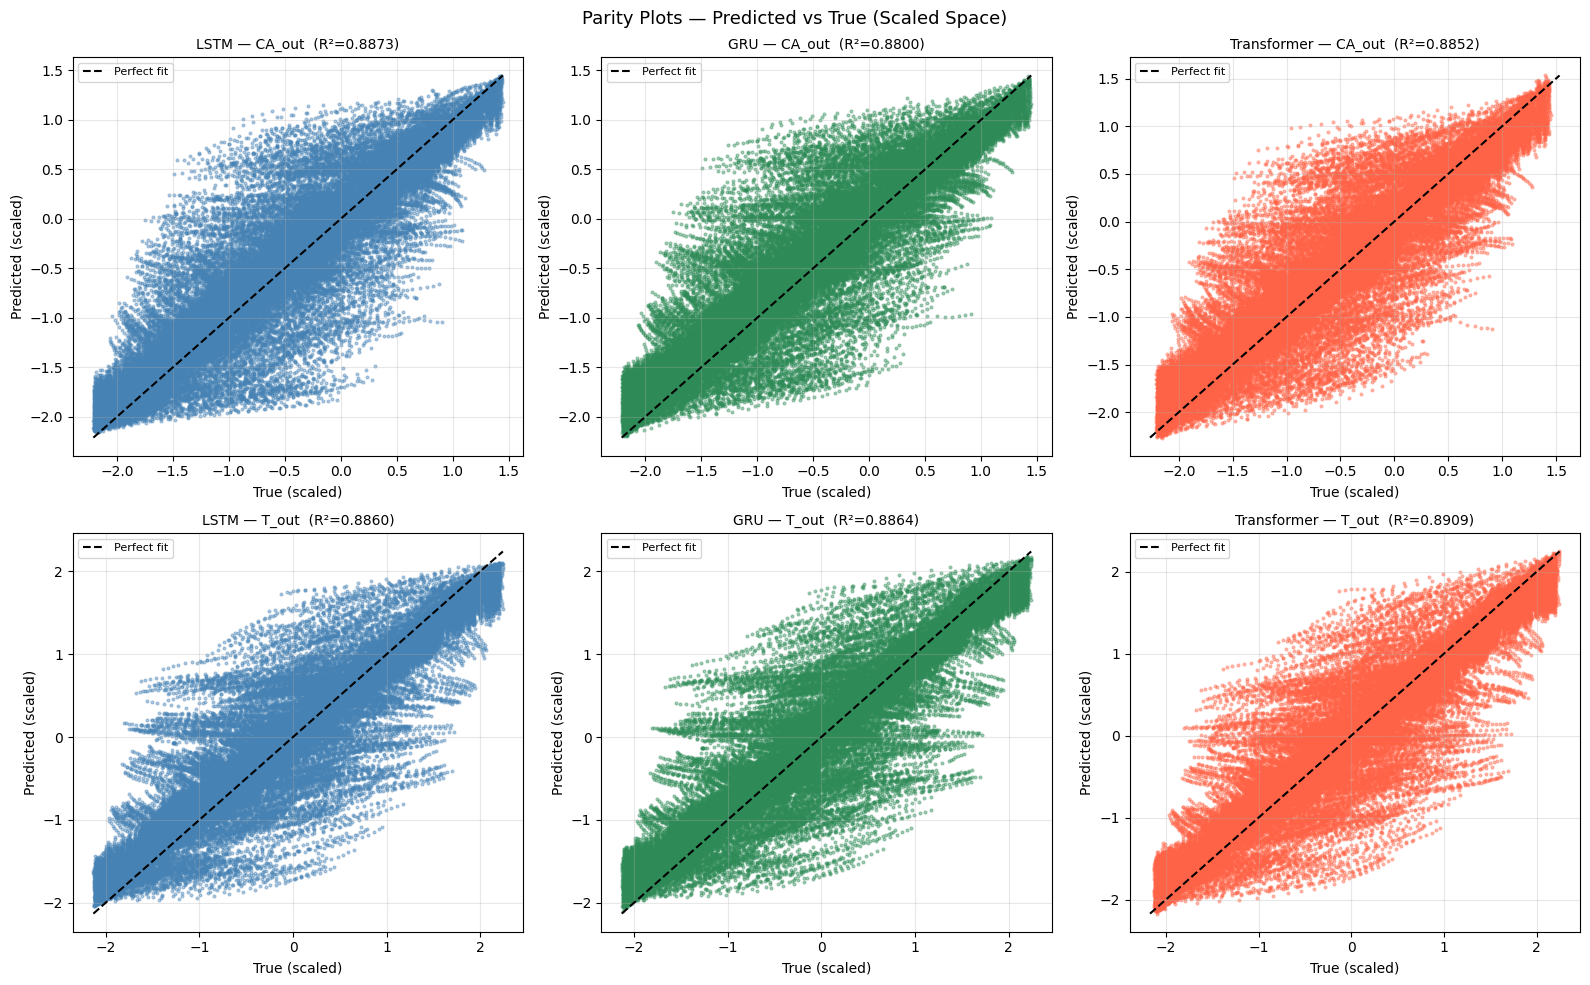

In [20]:
# Parity (Scatter) Plots
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
titles = ["LSTM", "GRU", "Transformer"]
all_preds = [lstm_preds, gru_preds, trans_preds]
output_names = ["CA_out", "T_out"]

for col, (name, preds) in enumerate(zip(titles, all_preds)):
    for row, oname in enumerate(output_names):
        ax = axes[row][col]
        true_vals = trans_targets[:, row]
        pred_vals = preds[:, row]

        # Parity scatter
        ax.scatter(true_vals, pred_vals, s=4, alpha=0.4,
                   color=["steelblue","seagreen","tomato"][col])

        # Perfect prediction line
        lims = [min(true_vals.min(), pred_vals.min()),
                max(true_vals.max(), pred_vals.max())]
        ax.plot(lims, lims, "k--", lw=1.5, label="Perfect fit")

        # R² score
        ss_res = np.sum((true_vals - pred_vals) ** 2)
        ss_tot = np.sum((true_vals - true_vals.mean()) ** 2)
        r2 = 1 - ss_res / ss_tot

        ax.set_title(f"{name} — {oname}  (R²={r2:.4f})", fontsize=10)
        ax.set_xlabel("True (scaled)")
        ax.set_ylabel("Predicted (scaled)")
        ax.legend(fontsize=8)
        ax.grid(True, alpha=0.3)

plt.suptitle("Parity Plots — Predicted vs True (Scaled Space)", fontsize=13)
plt.tight_layout()
plt.savefig("parity_plots.png", dpi=150, bbox_inches="tight")
plt.show()


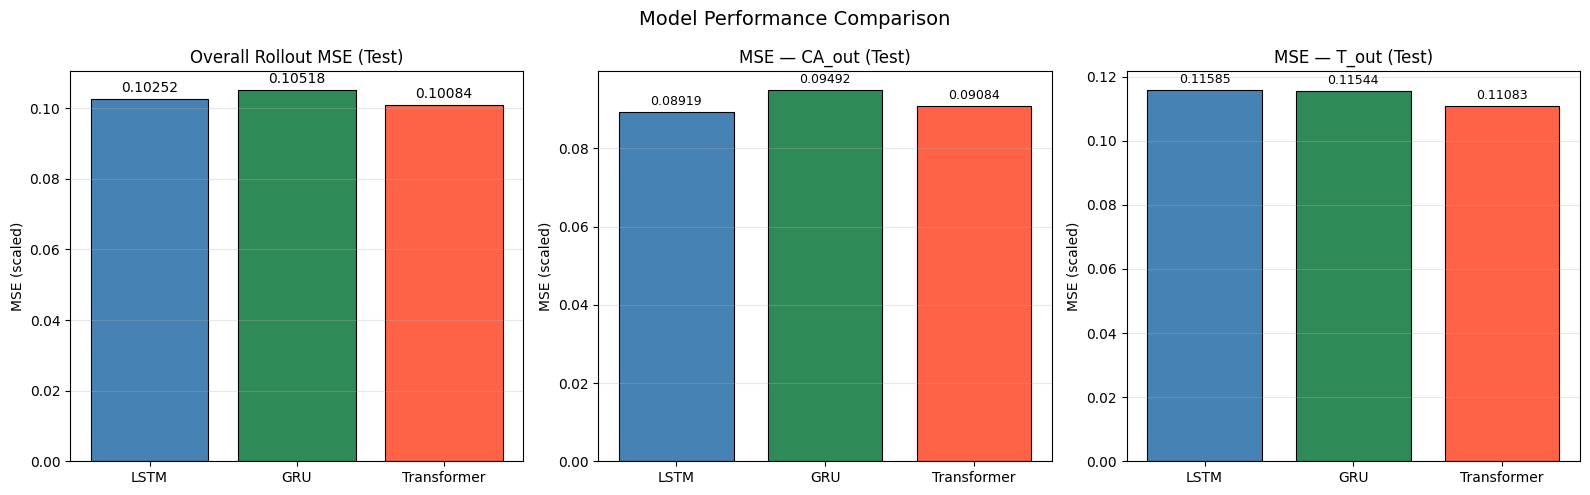

In [21]:
#Model Comparison Bar Chart
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# ── Overall rollout MSE ─────────────────────────────────────
names  = ["LSTM", "GRU", "Transformer"]
scores = [lstm_mse, gru_mse, trans_mse]
cols   = ["steelblue", "seagreen", "tomato"]

bars = axes[0].bar(names, scores, color=cols, edgecolor="black", linewidth=0.8)
axes[0].bar_label(bars, fmt="%.5f", padding=3, fontsize=10)
axes[0].set_title("Overall Rollout MSE (Test)", fontsize=12)
axes[0].set_ylabel("MSE (scaled)"); axes[0].grid(axis="y", alpha=0.3)

# ── Per-output MSE ─────────────────────────────────────────
all_preds  = [lstm_preds, gru_preds, trans_preds]
x_pos = np.arange(len(names))
width = 0.35

for ax, oi, oname in zip(axes[1:], [0, 1], ["CA_out", "T_out"]):
    mse_vals = [np.mean((p[:, oi] - trans_targets[:, oi])**2) for p in all_preds]
    brs = ax.bar(x_pos, mse_vals, width*2.2, color=cols,
                 edgecolor="black", linewidth=0.8)
    ax.bar_label(brs, fmt="%.5f", padding=3, fontsize=9)
    ax.set_xticks(x_pos); ax.set_xticklabels(names)
    ax.set_title(f"MSE — {oname} (Test)", fontsize=12)
    ax.set_ylabel("MSE (scaled)"); ax.grid(axis="y", alpha=0.3)

plt.suptitle("Model Performance Comparison", fontsize=14)
plt.tight_layout()
plt.savefig("model_comparison.png", dpi=150, bbox_inches="tight")
plt.show()
